# 🧠 Convolutional Neural Networks (CNN) — From Basics to Advanced

---

## 🔹 1. What is a CNN?

A **Convolutional Neural Network (CNN)** is a type of deep learning model designed to process **grid-like data**, especially images.

👉 It automatically learns:

* patterns
* features
* spatial hierarchies

---

## 🔹 2. Why CNN instead of simple Neural Networks?

### Problems with Fully Connected Networks:

* Too many parameters
* Ignore spatial relationships
* Overfitting on images

### CNN solves this by:

* Using **local connectivity**
* Sharing weights
* Extracting spatial features

---

## 🔹 3. Image Representation

An image is represented as:

* Grayscale → `H × W × 1`
* RGB → `H × W × 3`

Each pixel = numerical value (0–255 or normalized 0–1)

---

## 🔹 4. Core Components of CNN

---

### 🔸 (1) Convolution Layer

Applies **filters (kernels)** to extract features.

#### Operation:

* Slide filter over image
* Perform element-wise multiplication
* Sum values → feature map

👉 Detects:

* edges
* textures
* patterns

---

### 🔸 (2) Activation Function

Introduces **non-linearity**

Common functions:

* ReLU → `f(x) = max(0, x)`
* Sigmoid
* Tanh
* Leaky ReLU / PReLU

👉 Without this, CNN becomes linear (useless for complex tasks)

---

### 🔸 (3) Pooling Layer

Reduces spatial size

Types:

* Max Pooling → takes max value
* Average Pooling

👉 Benefits:

* Reduces computation
* Controls overfitting
* Keeps important features

---

### 🔸 (4) Fully Connected Layer (FC)

* Flattens feature maps
* Performs final classification

---

## 🔹 5. CNN Architecture Flow

```
Input Image
   ↓
Convolution
   ↓
Activation (ReLU)
   ↓
Pooling
   ↓
(Repeat multiple times)
   ↓
Flatten
   ↓
Fully Connected Layer
   ↓
Output (Softmax / Sigmoid)
```

---

## 🔹 6. Important Concepts

---

### 🔸 Stride

* Step size of filter movement

---

### 🔸 Padding

* Adding zeros around image
* Prevents shrinking

Types:

* Valid (no padding)
* Same (output same size)

---

### 🔸 Feature Maps

* Output of convolution
* Represent learned patterns

---

## 🔹 7. Training a CNN

Steps:

1. Forward pass
2. Compute loss
3. Backpropagation
4. Update weights (Gradient Descent)

---

## 🔹 8. Loss Functions

* Classification → Cross Entropy
* Binary → Binary Cross Entropy

---

## 🔹 9. Advanced Concepts

---

### 🔸 (1) Deep CNNs

* Multiple convolution layers
* Learn hierarchical features

---

### 🔸 (2) Transfer Learning

* Use pretrained models
* Fine-tune for new tasks

Examples:

* VGG
* ResNet
* Inception

---

### 🔸 (3) Data Augmentation

* Flip, rotate, crop images
* Improves generalization

---

### 🔸 (4) Batch Normalization

* Stabilizes learning
* Faster convergence

---

### 🔸 (5) Dropout

* Randomly disables neurons
* Prevents overfitting

---

### 🔸 (6) Residual Connections

* Used in very deep networks
* Helps avoid vanishing gradient

---

## 🔹 10. Applications of CNN

* Image classification
* Object detection
* Face recognition
* Medical imaging
* Self-driving cars

---

## 🔹 11. Key Intuition

👉 CNN learns like this:

* Early layers → edges
* Middle layers → shapes
* Deep layers → objects

---

## 🔹 12. Advantages

✔ Automatic feature extraction
✔ High accuracy on images
✔ Efficient parameter usage

---

## 🔹 13. Limitations

❌ Requires large data
❌ Computationally expensive
❌ Hard to interpret

---

## 🔹 14. One-Line Summary

👉 **CNN is a deep learning model that automatically extracts and learns hierarchical features from images using convolution operations.**

---


# Implementation 

In [34]:
import tensorflow as tf 
from tensorflow import keras 
import matplotlib.pyplot as plt

In [35]:
# load the dataset 
(X_train, y_train) , ( X_test , y_test ) = keras.datasets.mnist.load_data()

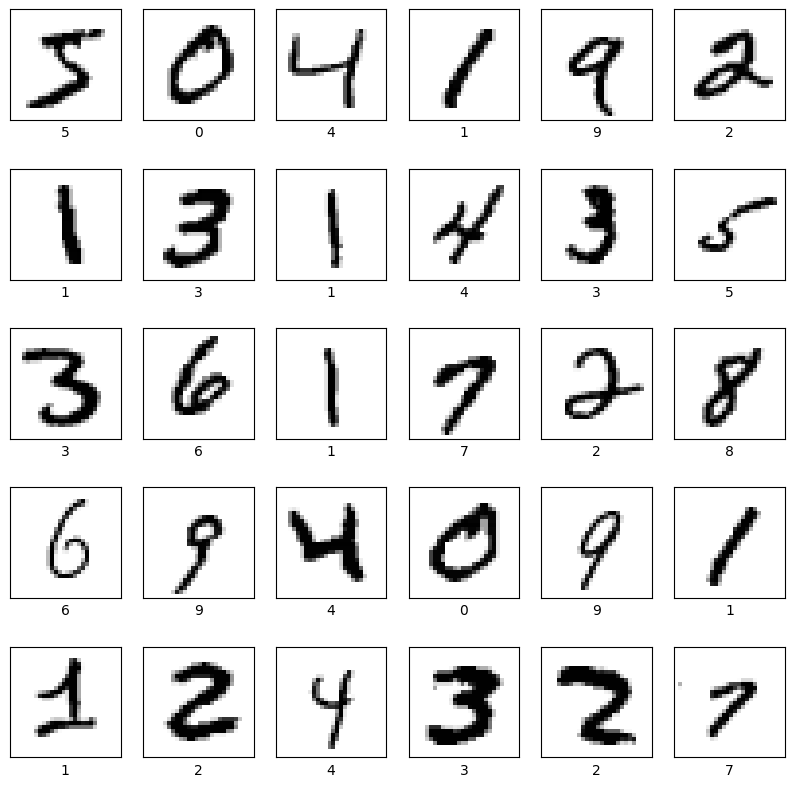

In [36]:
plt.figure(figsize=(10,10))

for i in range(30):
    plt.subplot(5 , 6 , i+1)
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    plt.imshow(X_train[i], cmap=plt.cm.binary)
    plt.xlabel(y_train[i])
plt.show()

In [37]:
print(len(X_train))
print(len(X_test))


60000
10000


In [38]:
X_train.shape

(60000, 28, 28)

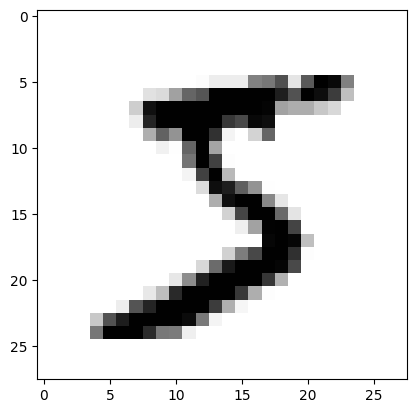

In [39]:
plt.imshow(X_train[0], cmap=plt.cm.binary)

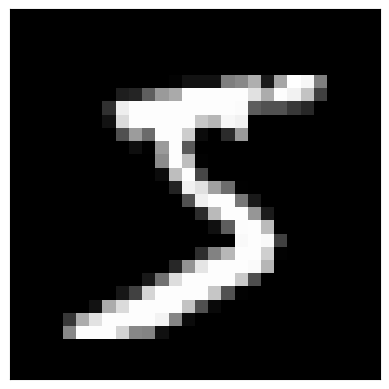

Pixel values:
  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0 
  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0 
  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0 
  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0 
  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0 
  0   0   0   0   0   0   0   0   0   0   0   0   3  18  18  18 126 136 175  26 166 255 247 127   0   0   0   0 
  0   0   0   0   0   0   0   0  30  36  94 154 170 253 253 253 253 253 225 172 253 242 195  64   0   0   0   0 
  0   0   0   0   0   0   0  49 238 253 253 253 253 253 253 253 253 251  93  82  82  56  39   0   0   0   0   0 
  0   0   0   0   0   0   0  18 219 253 253 253 253 253 198 182 247 241   0   0   

In [40]:
 # Display the first image in the dataset as a data matrix
plt.imshow(X_train[0], cmap="gray")
plt.xticks([])
plt.yticks([])
plt.grid(False)
plt.show()

# Display the values of each pixel in the image
print("Pixel values:")
for row in X_train[0]:
    for pixel in row:
        print("{:3}".format(pixel), end=" ")
    print()

### Normalize image data in CNN
 

* Convert to **float32** → needed for decimal computations
* Divide by **255** → scale pixels from **[0,255] → [0,1]**

#### Benefits:

* Faster training
* Stable gradients
* Better model performance
 


In [41]:
X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0


Pixel values after normalization:
0.000 0.000 0.000 0.000 0.000 0.000 0.000 0.000 0.000 0.000 0.000 0.000 0.000 0.000 0.000 0.000 0.000 0.000 0.000 0.000 0.000 0.000 0.000 0.000 0.000 0.000 0.000 0.000 
0.000 0.000 0.000 0.000 0.000 0.000 0.000 0.000 0.000 0.000 0.000 0.000 0.000 0.000 0.000 0.000 0.000 0.000 0.000 0.000 0.000 0.000 0.000 0.000 0.000 0.000 0.000 0.000 
0.000 0.000 0.000 0.000 0.000 0.000 0.000 0.000 0.000 0.000 0.000 0.000 0.000 0.000 0.000 0.000 0.000 0.000 0.000 0.000 0.000 0.000 0.000 0.000 0.000 0.000 0.000 0.000 
0.000 0.000 0.000 0.000 0.000 0.000 0.000 0.000 0.000 0.000 0.000 0.000 0.000 0.000 0.000 0.000 0.000 0.000 0.000 0.000 0.000 0.000 0.000 0.000 0.000 0.000 0.000 0.000 
0.000 0.000 0.000 0.000 0.000 0.000 0.000 0.000 0.000 0.000 0.000 0.000 0.000 0.000 0.000 0.000 0.000 0.000 0.000 0.000 0.000 0.000 0.000 0.000 0.000 0.000 0.000 0.000 
0.000 0.000 0.000 0.000 0.000 0.000 0.000 0.000 0.000 0.000 0.000 0.000 0.012 0.071 0.071 0.071 0.494 0.533 0.686 0.102 

<Figure size 640x480 with 0 Axes>

<Axes: >

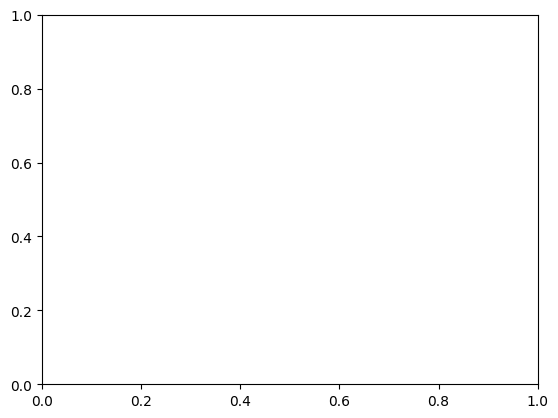

In [42]:
# Display the values of each pixel in the image after normalization
print("\nPixel values after normalization:")
for row in X_train[0]:
    for pixel in row:
        print("{:0.3f}".format(pixel), end=" ")
    print()
    
# Reshape the images to have a channel dimension
x_train = X_train.reshape(X_train.shape[0], 28, 28, 1)
x_test = X_test.reshape(X_test.shape[0], 28, 28, 1)
# Display the complete output of the cell
display(plt.gcf())
display(plt.gca())

## Build the model 


In [52]:
import tensorflow as tf 
from tensorflow.keras import layers 

input_layer = tf.keras.layers.Input(shape=(28, 28, 1)) # 28x28 pixel images with a single color channel


model = tf.keras.Sequential([ 
    input_layer , 
    layers.Conv2D(filters = 10 , kernel_size = (3,3 ) , activation = 'relu'  ),  # convolutional layer 
# filter : the number of output filters in the convolution
# kernel_size : the height and width of the 2D convolution window

    layers.Conv2D(filters = 10 , kernel_size = (3,3) , activation = 'relu'), # convolutional layer

    layers.MaxPooling2D(), # pooling layer : reduces the spatial dimensions of the output from the convolutional layers

    layers.Conv2D(filters = 10 , kernel_size = (3,3) , activation = 'relu' ), # convolutional layer
    layers.Conv2D(filters = 10 , kernel_size = (3,3) , activation = 'relu' ), # convolutional layer
    layers.MaxPooling2D(), # pooling layer

    layers.Flatten(), # flatten layer : converts the 2D output from the convolutional layers into a 1D vector
    layers.Dense(10 , activation = 'softmax' ) # output layer with 10 units (one for each class) and softmax activation function



])

In [53]:
model.summary()

Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_24 (Conv2D)              │ (None, 26, 26, 10)     │           100 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_25 (Conv2D)              │ (None, 24, 24, 10)     │           910 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_12 (MaxPooling2D) │ (None, 12, 12, 10)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_26 (Conv2D)              │ (None, 10, 10, 10)     │           910 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_27 (Conv2D)              │ (None, 8, 8, 10)       │           910 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_13 (MaxPooling2D) │ (None, 4, 4, 10)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_6 (Flatten)             │ (None, 160)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 10)             │         1,610 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,440 (17.34 KB)

 Trainable params: 4,440 (17.34 KB)

 Non-trainable params: 0 (0.00 B)

In [54]:
# Compile the model 

model.compile(optimizer = 'adam' , loss = 'sparse_categorical_crossentropy' , metrics = ['accuracy'] )


# Train the model
model.fit(x_train , y_train , epochs = 5 , batch_size = 64 , validation_data = (x_test , y_test) )

# Evaluate the model on the test set

test_loss , test_acc = model.evaluate(x_test , y_test)

print("Test accuracy : " , test_acc)
print("Test loss : " , test_loss)

Epoch 1/5


I0000 00:00:1777027914.821739   93959 service.cc:153] XLA service 0x7202f0016e20 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1777027914.821790   93959 service.cc:161]   StreamExecutor [0]: NVIDIA GeForce RTX 5050 Laptop GPU, Compute Capability 12.0a (Driver: 13.0.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.21.0)
I0000 00:00:1777027914.908058   93959 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1777027915.258540   93959 cuda_dnn.cc:461] Loaded cuDNN version 92100
I0000 00:00:1777027915.296279   93959 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_2008__.31


  9/938 ━━━━━━━━━━━━━━━━━━━━ 14s 15ms/step - accuracy: 0.1545 - loss: 2.3077 

I0000 00:00:1777027926.242526   93959 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


934/938 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.7950 - loss: 0.6808

I0000 00:00:1777027939.790589   93959 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_2008__.31


938/938 ━━━━━━━━━━━━━━━━━━━━ 48s 35ms/step - accuracy: 0.9078 - loss: 0.3077 - val_accuracy: 0.9703 - val_loss: 0.0910
Epoch 2/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 15s 16ms/step - accuracy: 0.9701 - loss: 0.0981 - val_accuracy: 0.9829 - val_loss: 0.0617
Epoch 3/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 14s 15ms/step - accuracy: 0.9768 - loss: 0.0746 - val_accuracy: 0.9822 - val_loss: 0.0539
Epoch 4/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 15s 16ms/step - accuracy: 0.9802 - loss: 0.0631 - val_accuracy: 0.9850 - val_loss: 0.0487
Epoch 5/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 15s 16ms/step - accuracy: 0.9825 - loss: 0.0561 - val_accuracy: 0.9859 - val_loss: 0.0426
313/313 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - accuracy: 0.9859 - loss: 0.0426
Test accuracy :  0.9858999848365784
Test loss :  0.042575567960739136


In [ ]:
 
img = X_test[0]
print(img.shape)

# rehape the image to (28, 28, 1)
img = img.reshape((28, 28, 1))
print(img.shape)

(28, 28)
(28, 28, 1)


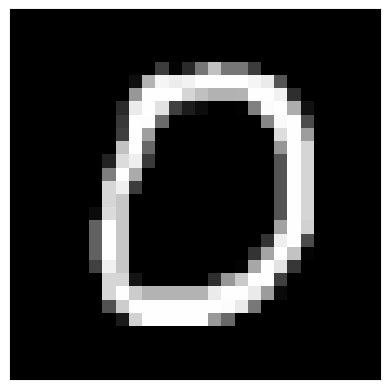

In [64]:
plt.imshow(img, cmap="gray")
plt.xticks([])
plt.yticks([])
plt.grid(False)
plt.show()

In [65]:
# predict the image
predictions = model.predict(img.reshape(1, 28, 28, 1))
print(predictions)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step
[[9.9999917e-01 6.9834736e-13 1.5931937e-07 1.6290799e-11 2.4288479e-13
  5.4220525e-08 5.8512614e-07 5.0534188e-11 1.1238665e-07 2.1171996e-08]]


In [66]:
print(predictions[:,7])

[5.0534188e-11]


In [67]:
print(f"The model predicts that this image is a {predictions.argmax()}.")

The model predicts that this image is a 0.
